# Instituto Federal do Espírito Santo (IFES) – Campus Serra
### Programa de Pós-Graduação em Computação Aplicada (PPComp) – Mestrado

**Disciplina:** Redes Neurais Artificiais (2026/2)
**Professor:** Francisco de Assis Boldt
**Aluno:** Leonardo Cruz de Andrade
**Data de entrega:** 18 de novembro de 2026

## Atividade 02 – CNN no MNIST a partir dos arquivos originais

Nas aulas o MNIST foi carregado com `keras.datasets.mnist.load_data()`, que já entrega os arrays prontos. Aqui eu baixo os quatro arquivos originais da base (formato IDX, compactados com gzip), escrevo a leitura deles, faço o pré-processamento e treino uma rede convolucional em PyTorch. Para ter uma referência, treino também uma rede só com camadas densas, como a da `aula07c`.

**Organização do notebook**
1. A base MNIST e o formato IDX
2. Download e conferência dos arquivos
3. Leitura dos arquivos IDX
4. Um olhar sobre os dados
5. Pré-processamento e divisão treino/validação
6. Modelos: rede densa de referência e CNN
7. Treinamento
8. Avaliação no conjunto de teste
9. Análise dos erros
10. Conclusões

Código de referência da disciplina: [fboldt/aulasann](https://github.com/fboldt/aulasann) (Aula 07).

## 1. A base MNIST e o formato IDX

O MNIST foi montado por LeCun, Cortes e Burges a partir de duas bases do NIST: a Special Database 3, escrita por funcionários do Census Bureau, e a Special Database 1, escrita por estudantes do ensino médio. Cada dígito foi redimensionado para caber numa caixa de $20 \times 20$ pixels, mantendo a proporção, e depois centralizado pelo centro de massa numa imagem de $28 \times 28$ em tons de cinza (0 é o fundo e 255 o traço). São 60.000 imagens de treino e 10.000 de teste, distribuídas em quatro arquivos:

| Arquivo | Conteúdo |
| :--- | :--- |
| `train-images-idx3-ubyte.gz` | 60.000 imagens de treino |
| `train-labels-idx1-ubyte.gz` | 60.000 rótulos de treino |
| `t10k-images-idx3-ubyte.gz` | 10.000 imagens de teste |
| `t10k-labels-idx1-ubyte.gz` | 10.000 rótulos de teste |

O formato IDX é simples: um cabeçalho de inteiros de 32 bits em *big-endian* seguido dos dados em bytes sem sinal.

- **Imagens:** *magic number* 2051 (`0x00000803`: tipo `0x08` = unsigned byte, `0x03` = três dimensões), depois o número de imagens, o número de linhas e o número de colunas. São 16 bytes de cabeçalho e, em seguida, $N \times 28 \times 28$ pixels.
- **Rótulos:** *magic number* 2049 (`0x00000801`) e o número de rótulos, ou seja, 8 bytes de cabeçalho seguidos de $N$ bytes com valores de 0 a 9.

In [1]:
import os
import gzip
import copy
import struct
import hashlib
import time
import urllib.request

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Os resultados do texto foram obtidos em CPU. Em GPU o treino é mais rápido,
# mas os números mudam um pouco; para usá-la, troque USAR_GPU para True.
USAR_GPU = False
device = torch.device('cuda' if USAR_GPU and torch.cuda.is_available() else 'cpu')
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.14.1+cpu | dispositivo: cpu


## 2. Download e conferência dos arquivos

O endereço original (`yann.lecun.com/exdb/mnist`) costuma recusar downloads automáticos, então deixei mais dois espelhos que distribuem os mesmos arquivos. O download é feito para um arquivo temporário e só é renomeado no final, para não sobrar arquivo pela metade se a conexão cair. Se o arquivo já existir na pasta `data_raw`, ele não é baixado de novo.

Para garantir que os arquivos são os originais, comparo o MD5 de cada um com os valores publicados (os mesmos usados pelo `torchvision` para validar o download).

In [2]:
DATA_DIR = os.path.join(os.getcwd(), "data_raw")
os.makedirs(DATA_DIR, exist_ok=True)

# nome do arquivo -> MD5 esperado
MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz":  "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz":  "ec29112dd5afa0611ce80d1b7f02629c",
}

MIRRORS = [
    "http://yann.lecun.com/exdb/mnist/",
    "https://ossci-datasets.s3.amazonaws.com/mnist/",
    "https://storage.googleapis.com/cvdf-datasets/mnist/",
]

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()

def baixar(nome):
    destino = os.path.join(DATA_DIR, nome)
    if os.path.exists(destino):
        return "já estava na pasta"
    for base in MIRRORS:
        try:
            req = urllib.request.Request(base + nome, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=30) as resp, open(destino + ".part", "wb") as f:
                f.write(resp.read())
            os.replace(destino + ".part", destino)
            return "baixado de " + base
        except Exception as e:
            print(f"  falhou em {base}: {e}")
    raise RuntimeError(f"Não foi possível baixar {nome}")

for nome, md5_esperado in MNIST_FILES.items():
    origem = baixar(nome)
    caminho = os.path.join(DATA_DIR, nome)
    ok = md5(caminho) == md5_esperado
    print(f"{nome:28s} {os.path.getsize(caminho):>10,d} bytes  MD5 {'ok' if ok else 'DIFERENTE'}  ({origem})")
    if not ok:
        raise ValueError(f"MD5 de {nome} não confere; apague o arquivo e rode de novo.")

train-images-idx3-ubyte.gz    9,912,422 bytes  MD5 ok  (já estava na pasta)
train-labels-idx1-ubyte.gz       28,881 bytes  MD5 ok  (já estava na pasta)
t10k-images-idx3-ubyte.gz     1,648,877 bytes  MD5 ok  (já estava na pasta)
t10k-labels-idx1-ubyte.gz         4,542 bytes  MD5 ok  (já estava na pasta)


## 3. Leitura dos arquivos IDX

As duas funções abaixo abrem o `.gz` com `gzip`, leem o cabeçalho com `struct.unpack` (`>` indica *big-endian* e `I` um inteiro de 32 bits sem sinal) e transformam o resto do arquivo num array com `np.frombuffer`. Além do *magic number*, confiro se a quantidade de bytes lida bate com o que o cabeçalho anuncia; se o arquivo estivesse truncado, o erro apareceria aqui e não lá na frente, no treino.

In [3]:
def ler_imagens_idx(caminho):
    with gzip.open(caminho, "rb") as f:
        magic, n, linhas, colunas = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError(f"{caminho}: magic number {magic}, esperado 2051")
        dados = np.frombuffer(f.read(), dtype=np.uint8)
    if dados.size != n * linhas * colunas:
        raise ValueError(f"{caminho}: {dados.size} bytes, esperado {n * linhas * colunas}")
    print(f"{os.path.basename(caminho)}: magic={magic}, n={n}, {linhas}x{colunas}")
    return dados.reshape(n, linhas, colunas)

def ler_rotulos_idx(caminho):
    with gzip.open(caminho, "rb") as f:
        magic, n = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError(f"{caminho}: magic number {magic}, esperado 2049")
        dados = np.frombuffer(f.read(), dtype=np.uint8)
    if dados.size != n:
        raise ValueError(f"{caminho}: {dados.size} rótulos, esperado {n}")
    print(f"{os.path.basename(caminho)}: magic={magic}, n={n}")
    return dados

X_train_raw = ler_imagens_idx(os.path.join(DATA_DIR, "train-images-idx3-ubyte.gz"))
y_train_raw = ler_rotulos_idx(os.path.join(DATA_DIR, "train-labels-idx1-ubyte.gz"))
X_test_raw = ler_imagens_idx(os.path.join(DATA_DIR, "t10k-images-idx3-ubyte.gz"))
y_test_raw = ler_rotulos_idx(os.path.join(DATA_DIR, "t10k-labels-idx1-ubyte.gz"))

print()
print("treino:", X_train_raw.shape, X_train_raw.dtype, "| rótulos:", y_train_raw.shape)
print("teste: ", X_test_raw.shape, X_test_raw.dtype, "| rótulos:", y_test_raw.shape)
print("pixels entre", X_train_raw.min(), "e", X_train_raw.max())

train-images-idx3-ubyte.gz: magic=2051, n=60000, 28x28
train-labels-idx1-ubyte.gz: magic=2049, n=60000
t10k-images-idx3-ubyte.gz: magic=2051, n=10000, 28x28
t10k-labels-idx1-ubyte.gz: magic=2049, n=10000

treino: (60000, 28, 28) uint8 | rótulos: (60000,)
teste:  (10000, 28, 28) uint8 | rótulos: (10000,)
pixels entre 0 e 255


## 4. Um olhar sobre os dados

Antes de treinar, vale ver algumas imagens com os rótulos lidos, para confirmar que imagem e rótulo ficaram alinhados, e a quantidade de exemplos por dígito.

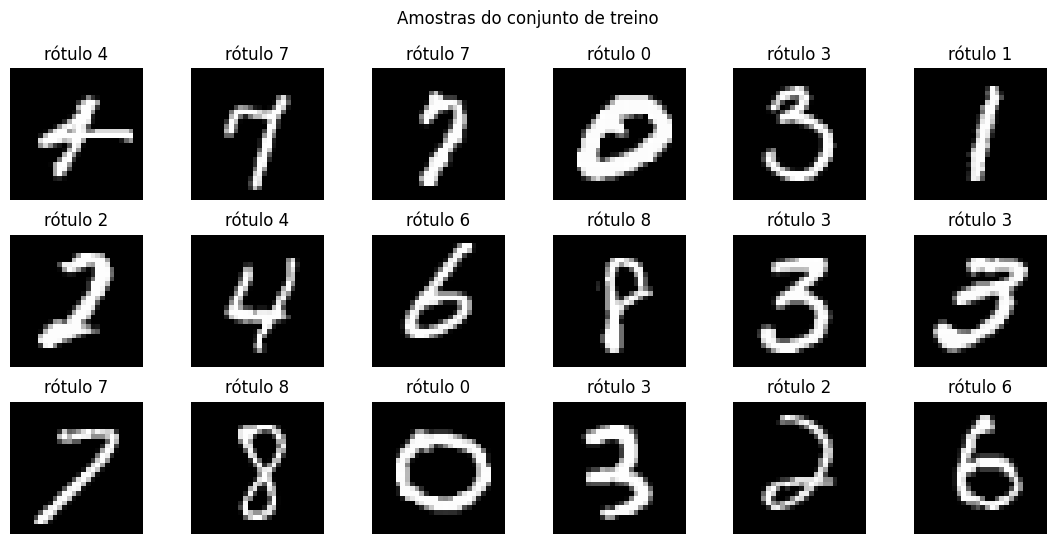

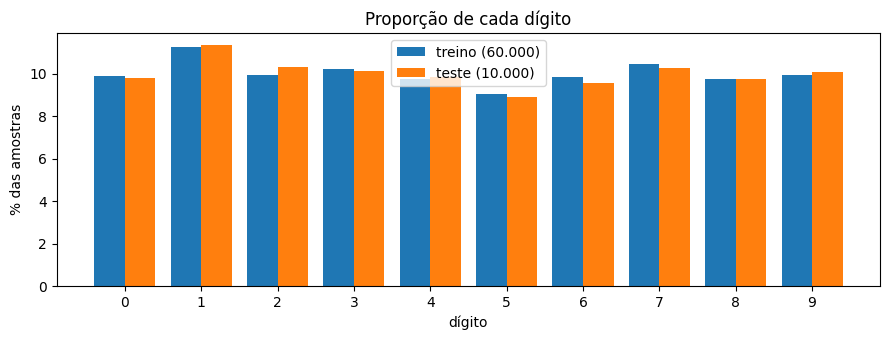

dígito:       0      1      2      3      4      5      6      7      8      9
treino:    5923   6742   5958   6131   5842   5421   5918   6265   5851   5949
teste:      980   1135   1032   1010    982    892    958   1028    974   1009


In [4]:
rng = np.random.default_rng(SEED)
amostra = rng.choice(len(X_train_raw), size=18, replace=False)

fig, axes = plt.subplots(3, 6, figsize=(11, 5.5))
for idx, ax in zip(amostra, axes.flat):
    ax.imshow(X_train_raw[idx], cmap="gray")
    ax.set_title(f"rótulo {y_train_raw[idx]}")
    ax.axis("off")
fig.suptitle("Amostras do conjunto de treino")
plt.tight_layout()
plt.show()

cont_treino = np.bincount(y_train_raw, minlength=10)
cont_teste = np.bincount(y_test_raw, minlength=10)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(np.arange(10) - 0.2, cont_treino / cont_treino.sum() * 100, width=0.4, label="treino (60.000)")
ax.bar(np.arange(10) + 0.2, cont_teste / cont_teste.sum() * 100, width=0.4, label="teste (10.000)")
ax.set_xticks(range(10))
ax.set_xlabel("dígito")
ax.set_ylabel("% das amostras")
ax.set_title("Proporção de cada dígito")
ax.legend()
plt.tight_layout()
plt.show()

print("dígito: ", " ".join(f"{d:>6d}" for d in range(10)))
print("treino: ", " ".join(f"{c:>6d}" for c in cont_treino))
print("teste:  ", " ".join(f"{c:>6d}" for c in cont_teste))

As classes estão razoavelmente equilibradas: o dígito mais frequente no treino é o 1 (6.742 exemplos) e o menos frequente é o 5 (5.421). As proporções no treino e no teste são parecidas, então a acurácia é uma métrica adequada aqui, sem precisar de ponderação por classe.

## 5. Pré-processamento e divisão treino/validação

O pré-processamento segue o que foi feito na `aula07d`:
- converter para `float32` e dividir por 255, levando os pixels para $[0, 1]$;
- acrescentar a dimensão de canal, porque a `nn.Conv2d` espera tensores no formato $(N, C, H, W)$, aqui $(N, 1, 28, 28)$.

Para acompanhar o treino sem tocar no teste, separo 10.000 imagens do treino para validação. A separação é aleatória e estratificada, mantendo a proporção de cada dígito. O conjunto de teste (`t10k`) fica guardado para a avaliação final.

Como conferência do pré-processamento, calculo a média e o desvio padrão dos pixels das 60.000 imagens de treino. Os valores conhecidos para o MNIST são 0,1307 e 0,3081, e são justamente os que aparecem na normalização dos exemplos oficiais do PyTorch.

In [5]:
X_train_all = X_train_raw.astype(np.float32) / 255.0
X_test = X_test_raw.astype(np.float32) / 255.0

print(f"média dos pixels: {X_train_all.mean():.4f} | desvio padrão: {X_train_all.std():.4f}")

idx_treino, idx_val = train_test_split(np.arange(len(y_train_raw)), test_size=10_000,
                                       stratify=y_train_raw, random_state=SEED)

def para_tensor(X, y):
    return TensorDataset(torch.from_numpy(X).unsqueeze(1), torch.from_numpy(y.astype(np.int64)))

ds_treino = para_tensor(X_train_all[idx_treino], y_train_raw[idx_treino])
ds_val = para_tensor(X_train_all[idx_val], y_train_raw[idx_val])
ds_teste = para_tensor(X_test, y_test_raw)

BATCH_SIZE = 128
val_loader = DataLoader(ds_val, batch_size=512)
test_loader = DataLoader(ds_teste, batch_size=512)

for nome, ds in [("treino", ds_treino), ("validação", ds_val), ("teste", ds_teste)]:
    print(f"{nome:10s} {tuple(ds.tensors[0].shape)}")

média dos pixels: 0.1307 | desvio padrão: 0.3081
treino     (50000, 1, 28, 28)
validação  (10000, 1, 28, 28)
teste      (10000, 1, 28, 28)


## 6. Modelos

### 6.1 Rede densa de referência

É a rede da `aula07c`: as 784 entradas achatadas, uma camada oculta de 512 neurônios com ReLU e a saída com 10 neurônios. Ela serve para medir quanto a convolução acrescenta.

### 6.2 Rede convolucional

Uma camada convolucional aplica o mesmo filtro pequeno em todas as posições da imagem:

$$Y_k(i, j) = b_k + \sum_{c} \sum_{m=0}^{K_h-1} \sum_{n=0}^{K_w-1} X_c(i + m, j + n) \, W_{k,c}(m, n)$$

Isso traz duas vantagens em relação à camada densa. Cada neurônio olha só para uma vizinhança da imagem, e o mesmo filtro é reaproveitado em toda a imagem, então um traço é detectado do mesmo jeito em qualquer posição e o número de pesos fica bem menor. O tamanho da saída de cada camada é

$$O = \left\lfloor \frac{I - K + 2P}{S} \right\rfloor + 1$$

com $I$ o tamanho da entrada, $K$ o tamanho do filtro, $P$ o *padding* e $S$ o *stride*.

A arquitetura parte da segunda CNN da `aula07d` (convoluções $3 \times 3$ com 32 e 64 filtros, intercaladas com *max pooling*). Acrescentei *batch normalization* depois de cada convolução e *dropout* antes e depois da camada densa:

| Camada | Saída |
| :--- | :--- |
| entrada | $1 \times 28 \times 28$ |
| Conv2d(1→32, 3×3, padding 1) + BatchNorm + ReLU | $32 \times 28 \times 28$ |
| MaxPool 2×2 | $32 \times 14 \times 14$ |
| Conv2d(32→64, 3×3, padding 1) + BatchNorm + ReLU | $64 \times 14 \times 14$ |
| MaxPool 2×2 + Dropout2d(0,25) | $64 \times 7 \times 7$ |
| Flatten | 3.136 |
| Linear(3136→128) + ReLU + Dropout(0,5) | 128 |
| Linear(128→10) | 10 (logits) |

A saída fica sem softmax porque a `nn.CrossEntropyLoss` já aplica o log-softmax internamente.

In [6]:
class RedeDensa(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.fc2 = nn.Linear(512, n_classes)

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(self.flatten(x))))


class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.drop_conv = nn.Dropout2d(0.25)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.drop_fc = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, n_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))   # 32 x 14 x 14
        x = self.pool(F.relu(self.bn2(self.conv2(x))))   # 64 x 7 x 7
        x = self.drop_conv(x)
        x = self.drop_fc(F.relu(self.fc1(self.flatten(x))))
        return self.fc2(x)


def n_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print(CNN())
print(f"\nparâmetros da rede densa: {n_parametros(RedeDensa()):,}".replace(",", "."))
print(f"parâmetros da CNN:        {n_parametros(CNN()):,}".replace(",", "."))

# conferindo o formato da saída de cada bloco com uma imagem
x = ds_treino.tensors[0][:1]
m = CNN().eval()
with torch.no_grad():
    a = m.pool(F.relu(m.bn1(m.conv1(x))))
    b = m.pool(F.relu(m.bn2(m.conv2(a))))
print("\nentrada", tuple(x.shape), "-> bloco 1", tuple(a.shape), "-> bloco 2", tuple(b.shape), "-> saída", tuple(m(x).shape))

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop_conv): Dropout2d(p=0.25, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (drop_fc): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

parâmetros da rede densa: 407.050
parâmetros da CNN:        421.834



entrada (1, 1, 28, 28) -> bloco 1 (1, 32, 14, 14) -> bloco 2 (1, 64, 7, 7) -> saída (1, 10)


As duas redes têm um número de parâmetros parecido (407 mil na densa e 422 mil na CNN), o que deixa a comparação mais justa: se a CNN for melhor, não é por ser muito maior. Na CNN, quase todos os parâmetros estão na camada `fc1` ($3136 \times 128 + 128 = 401.536$). As duas convoluções com as respectivas *batch normalizations* somam cerca de 19 mil.

## 7. Treinamento

As duas redes são treinadas da mesma forma que na `aula07d`: Adam com taxa de aprendizado 0,001, lotes de 128 imagens e entropia cruzada como função de custo,

$$\mathcal{L} = -\frac{1}{N} \sum_{i=1}^{N} \log \frac{e^{z_{i, y_i}}}{\sum_{j=0}^{9} e^{z_{i,j}}}$$

Treino por 10 épocas e, ao fim de cada uma, avalio no conjunto de validação. Guardo os pesos da época com menor custo de validação, como o `ModelCheckpoint(save_best_only=True)` usado na Aula 09, e são esses pesos que vão para o teste.

In [7]:
def avaliar(modelo, loader):
    modelo.eval()
    custo, acertos, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            saida = modelo(xb)
            custo += F.cross_entropy(saida, yb, reduction="sum").item()
            acertos += (saida.argmax(1) == yb).sum().item()
            total += len(yb)
    return custo / total, acertos / total


def treinar(modelo, epocas=10, lr=1e-3, seed=SEED):
    torch.manual_seed(seed)
    loader = DataLoader(ds_treino, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"treino_custo": [], "treino_acc": [], "val_custo": [], "val_acc": []}
    melhor = (np.inf, None, 0)
    inicio = time.time()

    for epoca in range(1, epocas + 1):
        modelo.train()
        custo, acertos, total = 0.0, 0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            otimizador.zero_grad()
            saida = modelo(xb)
            perda = F.cross_entropy(saida, yb)
            perda.backward()
            otimizador.step()
            custo += perda.item() * len(yb)
            acertos += (saida.argmax(1) == yb).sum().item()
            total += len(yb)

        val_custo, val_acc = avaliar(modelo, val_loader)
        hist["treino_custo"].append(custo / total)
        hist["treino_acc"].append(acertos / total)
        hist["val_custo"].append(val_custo)
        hist["val_acc"].append(val_acc)
        if val_custo < melhor[0]:
            melhor = (val_custo, copy.deepcopy(modelo.state_dict()), epoca)
        print(f"época {epoca:2d} | treino: custo {custo / total:.4f}, acc {acertos / total:.2%} | "
              f"validação: custo {val_custo:.4f}, acc {val_acc:.2%}")

    modelo.load_state_dict(melhor[1])
    print(f"tempo: {time.time() - inicio:.0f} s | pesos da época {melhor[2]} (menor custo de validação)")
    return hist, melhor[2]

In [8]:
torch.manual_seed(SEED)
densa = RedeDensa().to(device)
print("Rede densa")
hist_densa, ep_densa = treinar(densa)

Rede densa


época  1 | treino: custo 0.3451, acc 90.45% | validação: custo 0.1950, acc 94.44%


época  2 | treino: custo 0.1434, acc 95.84% | validação: custo 0.1348, acc 96.02%


época  3 | treino: custo 0.0938, acc 97.33% | validação: custo 0.1033, acc 97.00%


época  4 | treino: custo 0.0667, acc 98.06% | validação: custo 0.0952, acc 97.24%


época  5 | treino: custo 0.0493, acc 98.59% | validação: custo 0.0874, acc 97.40%


época  6 | treino: custo 0.0372, acc 98.99% | validação: custo 0.0764, acc 97.70%


época  7 | treino: custo 0.0288, acc 99.23% | validação: custo 0.0752, acc 97.75%


época  8 | treino: custo 0.0219, acc 99.45% | validação: custo 0.0757, acc 97.70%


época  9 | treino: custo 0.0163, acc 99.60% | validação: custo 0.0743, acc 97.92%


época 10 | treino: custo 0.0124, acc 99.72% | validação: custo 0.0787, acc 97.77%
tempo: 29 s | pesos da época 9 (menor custo de validação)


In [9]:
torch.manual_seed(SEED)
cnn = CNN().to(device)
print("CNN")
hist_cnn, ep_cnn = treinar(cnn)

CNN


época  1 | treino: custo 0.2567, acc 92.12% | validação: custo 0.0586, acc 98.17%


época  2 | treino: custo 0.1100, acc 96.75% | validação: custo 0.0469, acc 98.67%


época  3 | treino: custo 0.0865, acc 97.38% | validação: custo 0.0444, acc 98.73%


época  4 | treino: custo 0.0752, acc 97.71% | validação: custo 0.0472, acc 98.65%


época  5 | treino: custo 0.0660, acc 98.03% | validação: custo 0.0381, acc 98.97%


época  6 | treino: custo 0.0592, acc 98.27% | validação: custo 0.0364, acc 99.07%


época  7 | treino: custo 0.0533, acc 98.32% | validação: custo 0.0359, acc 98.94%


época  8 | treino: custo 0.0473, acc 98.47% | validação: custo 0.0356, acc 99.06%


época  9 | treino: custo 0.0439, acc 98.63% | validação: custo 0.0363, acc 99.06%


época 10 | treino: custo 0.0408, acc 98.73% | validação: custo 0.0339, acc 99.02%
tempo: 329 s | pesos da época 10 (menor custo de validação)


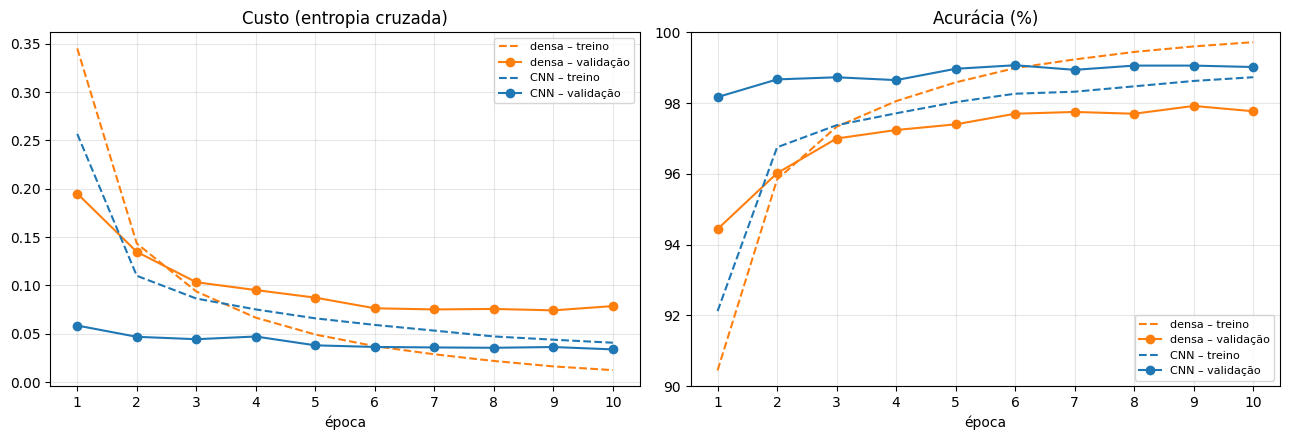

In [10]:
epocas = np.arange(1, len(hist_cnn["val_acc"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

for hist, nome, cor in [(hist_densa, "densa", "tab:orange"), (hist_cnn, "CNN", "tab:blue")]:
    ax1.plot(epocas, hist["treino_custo"], "--", color=cor, label=f"{nome} – treino")
    ax1.plot(epocas, hist["val_custo"], "o-", color=cor, label=f"{nome} – validação")
    ax2.plot(epocas, np.array(hist["treino_acc"]) * 100, "--", color=cor, label=f"{nome} – treino")
    ax2.plot(epocas, np.array(hist["val_acc"]) * 100, "o-", color=cor, label=f"{nome} – validação")

ax1.set_title("Custo (entropia cruzada)")
ax1.set_xlabel("época")
ax2.set_title("Acurácia (%)")
ax2.set_xlabel("época")
ax2.set_ylim(90, 100)
for ax in (ax1, ax2):
    ax.set_xticks(epocas)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

O comportamento das duas redes é bem diferente:
- **Rede densa.** Chega a 99,7% no treino, mas a validação para perto de 97,8% e o custo de validação volta a subir na última época. É o começo de um sobreajuste, e por isso os pesos guardados são os da época 9.
- **CNN.** Já na primeira época passa de 98% na validação e termina perto de 99%. O custo de validação ainda caía na época 10, então mais algumas épocas talvez ajudassem um pouco.

Na CNN, a acurácia de validação fica acima da de treino o tempo todo. Isso não indica erro na divisão dos dados. Durante o treino o *dropout* está ligado e desliga parte da rede a cada lote, e a acurácia de treino é a média ao longo da época, enquanto a rede ainda está mudando. Na validação a rede é usada inteira (`model.eval()`) e com os pesos do fim da época.

## 8. Avaliação no conjunto de teste

Com os pesos escolhidos pela validação, as duas redes são avaliadas nas 10.000 imagens de `t10k`, que não foram usadas em nenhum momento do treino.

In [11]:
def prever(modelo, loader):
    modelo.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in loader:
            probs.append(F.softmax(modelo(xb.to(device)), dim=1).cpu().numpy())
    return np.concatenate(probs)

prob_densa = prever(densa, test_loader)
prob_cnn = prever(cnn, test_loader)
pred_densa = prob_densa.argmax(1)
pred_cnn = prob_cnn.argmax(1)

for nome, pred in [("rede densa", pred_densa), ("CNN", pred_cnn)]:
    erros = (pred != y_test_raw).sum()
    print(f"{nome:10s} acurácia no teste: {(pred == y_test_raw).mean():.2%} ({erros} erros em 10.000)")

print("\nRelatório por dígito (CNN):")
print(classification_report(y_test_raw, pred_cnn, digits=4))

rede densa acurácia no teste: 97.93% (207 erros em 10.000)
CNN        acurácia no teste: 99.07% (93 erros em 10.000)

Relatório por dígito (CNN):
              precision    recall  f1-score   support

           0     0.9899    0.9959    0.9929       980
           1     0.9947    0.9965    0.9956      1135
           2     0.9942    0.9893    0.9917      1032
           3     0.9941    0.9950    0.9946      1010
           4     0.9939    0.9878    0.9908       982
           5     0.9866    0.9933    0.9899       892
           6     0.9958    0.9823    0.9890       958
           7     0.9846    0.9932    0.9889      1028
           8     0.9867    0.9867    0.9867       974
           9     0.9861    0.9861    0.9861      1009

    accuracy                         0.9907     10000
   macro avg     0.9906    0.9906    0.9906     10000
weighted avg     0.9907    0.9907    0.9907     10000



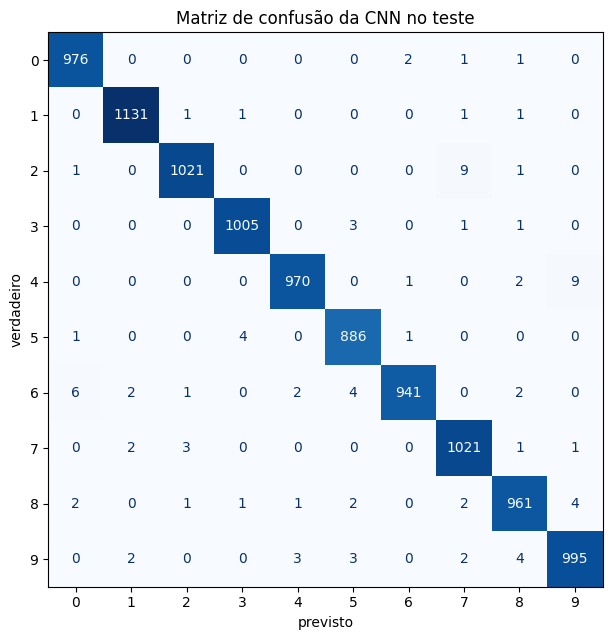

Confusões mais frequentes (verdadeiro -> previsto):
  4 -> 9: 9
  2 -> 7: 9
  6 -> 0: 6
  9 -> 8: 4
  8 -> 9: 4
  6 -> 5: 4


In [12]:
cm = confusion_matrix(y_test_raw, pred_cnn)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matriz de confusão da CNN no teste")
ax.set_xlabel("previsto")
ax.set_ylabel("verdadeiro")
plt.tight_layout()
plt.show()

fora = cm.copy()
np.fill_diagonal(fora, 0)
pares = sorted(((fora[i, j], i, j) for i in range(10) for j in range(10) if fora[i, j] > 0), reverse=True)
print("Confusões mais frequentes (verdadeiro -> previsto):")
for n, i, j in pares[:6]:
    print(f"  {i} -> {j}: {n}")

## 9. Análise dos erros

Abaixo estão os erros da CNN em que ela estava mais confiante, isto é, com a maior probabilidade atribuída à classe errada. São os casos mais interessantes para olhar, porque indicam se a rede está errando dígitos legíveis ou imagens que nem uma pessoa classificaria com certeza.

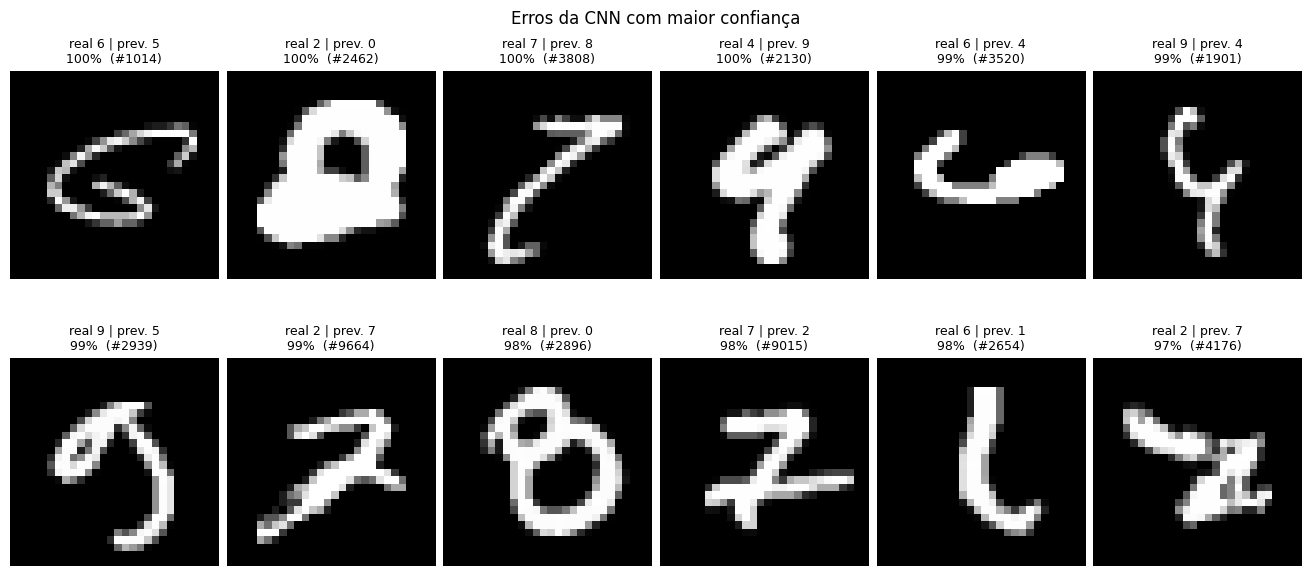

93 erros no total; confiança mediana nos erros: 76%
erros com confiança acima de 90%: 21
a rede densa erra 207 imagens; 54 delas também são erros da CNN


In [13]:
erros = np.where(pred_cnn != y_test_raw)[0]
conf_erro = prob_cnn[erros, pred_cnn[erros]]
mais_confiantes = erros[np.argsort(-conf_erro)][:12]

fig, axes = plt.subplots(2, 6, figsize=(13, 6), layout="constrained")
for idx, ax in zip(mais_confiantes, axes.flat):
    ax.imshow(X_test_raw[idx], cmap="gray")
    ax.set_title(f"real {y_test_raw[idx]} | prev. {pred_cnn[idx]}\n{prob_cnn[idx, pred_cnn[idx]]:.0%}  (#{idx})", fontsize=9)
    ax.axis("off")
fig.suptitle("Erros da CNN com maior confiança")
plt.show()

print(f"{len(erros)} erros no total; confiança mediana nos erros: {np.median(conf_erro):.0%}")
print(f"erros com confiança acima de 90%: {(conf_erro > 0.9).sum()}")
print(f"a rede densa erra {np.sum(pred_densa != y_test_raw)} imagens; "
      f"{np.sum((pred_densa != y_test_raw) & (pred_cnn != y_test_raw))} delas também são erros da CNN")

A CNN errou 93 das 10.000 imagens de teste. As confusões mais comuns, 4 com 9 e 2 com 7 (9 casos cada), além de 6 com 0, fazem sentido: são pares de dígitos que diferem por um detalhe pequeno, como o topo do 4 fechado ou aberto, ou o traço de baixo do 2.

Olhando os erros em que a rede estava mais confiante, boa parte das imagens é difícil até para uma pessoa:
- **Dígitos quase irreconhecíveis:** o 2 da imagem #2462 é praticamente uma mancha com um buraco, e o 6 da #3520 está deitado.
- **Traços que mudam o dígito:** o 4 da #2130 tem o topo fechado e parece um 9.
- **2 e 7:** o 7 cortado da #9015, com o traço no meio como se escreve no Brasil, ficou parecido com um Z. Já os 2 das #9664 e #4176 têm a base curta e inclinada e lembram um 7.

Ainda assim, há erros que uma pessoa não cometeria, como o 6 da #1014. Nesse caso a rede se apoiou na volta de cima do traço e deixou a de baixo de lado.

A confiança nos erros é menor do que nos acertos: a mediana é 76%, e só 21 dos 93 erros têm confiança acima de 90%. Das 93 imagens que a CNN errou, 54 também foram erradas pela rede densa, o que reforça que são casos difíceis e não falhas específicas da arquitetura.

## 10. Conclusões

**Dados.** Os quatro arquivos originais foram baixados, conferidos pelo MD5 e lidos diretamente do formato IDX, sem usar `keras.datasets` nem `torchvision.datasets`. A média (0,1307) e o desvio padrão (0,3081) dos pixels depois do pré-processamento batem com os valores conhecidos da base, um bom sinal de que leitura e normalização estão corretas.

**Resultados.** Com número de parâmetros parecido, a CNN acertou 99,07% do conjunto de teste e a rede densa 97,93%. São 93 erros contra 207, ou seja, a convolução eliminou mais da metade dos erros. Como referência, a CNN mais simples da `aula07d` chegou a 98,72% com 5 épocas. A diferença deve vir principalmente de três coisas: as camadas de *batch normalization* e *dropout*, o treino mais longo e a escolha da época pela validação.

**Treinamento.** A rede densa começou a sobreajustar nas últimas épocas: o treino seguiu melhorando enquanto a validação estacionou perto de 97,8%. A CNN não mostrou esse comportamento em 10 épocas, e o custo de validação ainda estava caindo no final.

**Erros.** Os erros que sobraram se concentram em pares parecidos (4/9, 2/7, 6/0), e vários são imagens ambíguas ou mal escritas.

**Limitações e próximos passos.** Os resultados são de uma única execução com semente fixa. Variando a semente, a acurácia deve oscilar alguns décimos de ponto percentual. Para melhorar, as opções naturais seriam treinar por mais épocas e usar *data augmentation*, com pequenas rotações e deslocamentos, que ajudaria justamente nos dígitos inclinados ou fora do centro que aparecem na lista de erros.

---
Leonardo Cruz de Andrade – PPComp/IFES, Campus Serra
Redes Neurais Artificiais (2026/2) – Prof. Francisco de Assis Boldt